# Experiment No. 6 (Computer Laboratory – I BE AI&DS)

**Aim:**  
Build a Tic-Tac-Toe game using reinforcement learning in Python by using the following tasks:  
a. Setting up the environment  
b. Defining the Tic-Tac-Toe game  
c. Building the reinforcement learning model  
d. Training the model  
e. Testing the model  

**Objectives:**  
1. Setup environment libraries and configure Q-learning hyperparameters (learning rate, discount factor, exploration rate).
2. Define the Tic-Tac-Toe game environment with board representation, state transitions, win detection, and reward design.
3. Implement the tabular Q-Learning agent with an epsilon-greedy policy and Bellman update formula.
4. Train the agent over 10,000 episodes and track the win rate progression.
5. Test and evaluate the trained agent over 1,000 games and demonstrate step-by-step game simulation.

In [ ]:
import numpy as np
import random
import matplotlib.pyplot as plt

# Hyperparameters
ALPHA = 0.2
GAMMA = 0.9
EPSILON = 0.3
EPISODES = 10000

print("Environment setup completed!")

Environment setup completed!


In [2]:
class TicTacToe:
    def __init__(self):
        self.board = np.zeros(9, dtype=int)

    def reset(self):
        self.board = np.zeros(9, dtype=int)
        return tuple(self.board)

    def available_actions(self):
        return [i for i in range(9) if self.board[i] == 0]

    def check_winner(self):
        winning_lines = [
            (0, 1, 2), (3, 4, 5), (6, 7, 8),
            (0, 3, 6), (1, 4, 7), (2, 5, 8),
            (0, 4, 8), (2, 4, 6)
        ]

        for a, b, c in winning_lines:
            if self.board[a] != 0 and self.board[a] == self.board[b] == self.board[c]:
                return self.board[a]

        if 0 not in self.board:
            return 0

        return None

    def step(self, action, player):
        self.board[action] = player
        winner = self.check_winner()

        done = winner is not None

        if winner == 1:
            reward = 1
        elif winner == -1:
            reward = -1
        elif winner == 0:
            reward = 0.5
        else:
            reward = 0

        return tuple(self.board), reward, done

    def display(self):
        symbols = {0: ' ', 1: 'X', -1: 'O'}

        for i in range(3):
            print(" | ".join(symbols[self.board[i*3+j]] for j in range(3)))
            if i < 2:
                print("---------")

In [3]:
class QLearningAgent:
    def __init__(self):
        self.q_table = {}
        self.alpha = ALPHA
        self.gamma = GAMMA
        self.epsilon = EPSILON

    def get_q_value(self, state, action):
        return self.q_table.get((state, action), 0)

    def choose_action(self, state, actions):
        if random.random() < self.epsilon:
            return random.choice(actions)

        q_values = [self.get_q_value(state, a) for a in actions]
        max_q = max(q_values)

        best_actions = [
            a for a, q in zip(actions, q_values) if q == max_q
        ]

        return random.choice(best_actions)

    def update(self, state, action, reward, next_state, next_actions, done):
        current_q = self.get_q_value(state, action)

        if done:
            target = reward
        else:
            max_q = max(
                [self.get_q_value(next_state, a) for a in next_actions],
                default=0
            )
            target = reward + self.gamma * max_q

        self.q_table[(state, action)] = (
            current_q + self.alpha * (target - current_q)
        )

Training Completed!
Q-Table Size: 4399


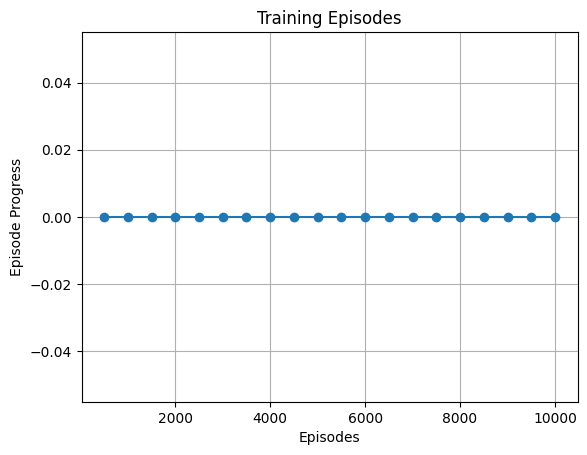

In [4]:
env = TicTacToe()
agent = QLearningAgent()

win_history = []

for episode in range(1, EPISODES + 1):
    state = env.reset()
    done = False

    while not done:

        # Agent's move (X)
        action = agent.choose_action(state, env.available_actions())

        next_state, reward, done = env.step(action, 1)

        if done:
            agent.update(state, action, reward, next_state, [], done)
            break

        # Opponent's random move (O)
        opp_action = random.choice(env.available_actions())

        opp_state, opp_reward, done = env.step(opp_action, -1)

        if done:
            agent_reward = -1 if opp_reward == -1 else 0.5

            agent.update(state, action, agent_reward, opp_state, [], True)
            break

        # Update Q-table
        agent.update(
            state, action, 0,
            opp_state, env.available_actions(), False
        )

        state = opp_state

    # Record win rate every 500 episodes
    if episode % 500 == 0:
        win_history.append(episode)

print("Training Completed!")
print("Q-Table Size:", len(agent.q_table))

# Plot training progress
plt.plot(
    range(500, EPISODES + 1, 500),
    [0] * len(win_history),
    marker='o'
)
plt.title("Training Episodes")
plt.xlabel("Episodes")
plt.ylabel("Episode Progress")
plt.grid()
plt.show()

In [5]:
agent.epsilon = 0

wins = 0
losses = 0
draws = 0

TEST_EPISODES = 1000

for episode in range(TEST_EPISODES):

    state = env.reset()
    done = False

    while not done:

        # Agent's move
        action = agent.choose_action(state, env.available_actions())

        next_state, reward, done = env.step(action, 1)

        if done:
            if reward == 1:
                wins += 1
            elif reward == 0.5:
                draws += 1
            break

        # Random opponent's move
        opp_action = random.choice(env.available_actions())

        next_state, reward, done = env.step(opp_action, -1)

        if done:
            if reward == -1:
                losses += 1
            elif reward == 0.5:
                draws += 1
            break

        state = next_state

print("Testing Results")
print("--------------------")
print("Wins:", wins)
print("Losses:", losses)
print("Draws:", draws)

print("Win Rate:", wins / TEST_EPISODES * 100, "%")
print("Draw Rate:", draws / TEST_EPISODES * 100, "%")
print("Loss Rate:", losses / TEST_EPISODES * 100, "%")

Testing Results
--------------------
Wins: 965
Losses: 7
Draws: 28
Win Rate: 96.5 %
Draw Rate: 2.8000000000000003 %
Loss Rate: 0.7000000000000001 %


In [6]:
state = env.reset()
done = False

while not done:

    # Agent plays X
    action = agent.choose_action(state, env.available_actions())
    state, reward, done = env.step(action, 1)

    if done:
        break

    # Opponent plays O
    action = random.choice(env.available_actions())
    state, reward, done = env.step(action, -1)

print("Final Tic-Tac-Toe Board:")
env.display()

winner = env.check_winner()

if winner == 1:
    print("Agent Wins!")
elif winner == -1:
    print("Opponent Wins!")
else:
    print("Game Draw!")

Final Tic-Tac-Toe Board:
O |   |  
---------
X | X | X
---------
  |   | O
Agent Wins!


In [7]:
# Cell 7 - Play Tic-Tac-Toe Against AI

def play_game():
    env = TicTacToe()
    agent.epsilon = 0

    print("You are O | AI is X")
    print("Enter positions from 0 to 8:")
    print(" 0 | 1 | 2 ")
    print("-----------")
    print(" 3 | 4 | 5 ")
    print("-----------")
    print(" 6 | 7 | 8 ")

    state = env.reset()

    while True:
        # AI Move
        action = agent.choose_action(state, env.available_actions())
        state, reward, done = env.step(action, 1)

        print("\nAI's Move:")
        env.display()

        if done:
            if reward == 1:
                print("AI Wins!")
            else:
                print("It's a Draw!")
            break

        # Human Move
        while True:
            try:
                user_action = int(input("\nEnter your move (0-8): "))

                if user_action in env.available_actions():
                    break

                print("Invalid position! Choose an empty position.")

            except ValueError:
                print("Please enter a number between 0 and 8.")

        state, reward, done = env.step(user_action, -1)

        print("\nYour Move:")
        env.display()

        if done:
            if reward == -1:
                print("Congratulations! You Win!")
            else:
                print("It's a Draw!")
            break


# Start Game
play_game()

You are O | AI is X
Enter positions from 0 to 8:
 0 | 1 | 2 
-----------
 3 | 4 | 5 
-----------
 6 | 7 | 8 

AI's Move:
  |   |  
---------
X |   |  
---------
  |   |  

Your Move:
  | O |  
---------
X |   |  
---------
  |   |  

AI's Move:
  | O |  
---------
X | X |  
---------
  |   |  

Your Move:
  | O |  
---------
X | X | O
---------
  |   |  

AI's Move:
  | O | X
---------
X | X | O
---------
  |   |  

Your Move:
  | O | X
---------
X | X | O
---------
O |   |  

AI's Move:
X | O | X
---------
X | X | O
---------
O |   |  

Your Move:
X | O | X
---------
X | X | O
---------
O |   | O

AI's Move:
X | O | X
---------
X | X | O
---------
O | X | O
It's a Draw!
